# DSCI552 HW7
Name: Yilin Chen  
Github Username: ychen501  
USC ID: 4414007229

In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import SVC, LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform
import matplotlib.pyplot as plt

## 1. Multi-class and Multi-Label Classification Using Support Vector Machines

### (a)
Download the Anuran Calls (MFCCs) Data Set from: https://archive.ics.uci.edu/ml/datasets/Anuran+Calls+%28MFCCs%29. Choose 70% of the data
randomly as the training set.

In [2]:
# load data set
frogs = pd.read_csv("../data/Anuran Calls (MFCCs)/Frogs_MFCCs.csv")

label_cols = ["Family", "Genus", "Species"]
X = frogs.drop(columns = label_cols+["RecordID"])
y = frogs[label_cols]

X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.7, random_state=42)

### (b)
Each instance has three labels: Families, Genus, and Species. Each of the labels has multiple classes. We wish to solve a multi-class and multi-label problem. One of the most important approaches to multi-label classification is to train a classifier for each label (binary relevance). We first try this approach:

### b(i)
Research exact match and hamming score/ loss methods for evaluating multilabel classification and use them in evaluating the classifiers in this problem

In [3]:
# n x 3 Family, Genus, Species
def exact_match(y_true, y_pred):
    all_correct = (np.asarray(y_true) == np.asarray(y_pred)).all(axis=1)
    return all_correct.mean()

def hamming_loss(y_true, y_pred):
    return (np.asarray(y_true) != np.asarray(y_pred)).mean()

def hamming_score(y_true, y_pred):
    return 1 - hamming_loss(y_true, y_pred)

**i answer**

- **Exact match**: the fraction of samples whose three predicted labels (Family, Genus, Species) are all correct.
- **Hamming loss**: the fraction of individual labels predicted wrong
- **Hamming score**: 1 − Hamming loss

### b(ii)

Train a SVM for each of the labels, using Gaussian kernels and one versus all classifiers. Determine the weight of the SVM penalty and the width of the Gaussian Kernel using 10 fold cross validation.1 You are welcome to try to solve the problem with both standardized 2 and raw attributes and report the results.

In [4]:
sigmas = np.arange(1, 21)/10
param_grid = {
    "estimator__C": 10.0 ** np.arange(-1, 7),
    "estimator__gamma": 1/(2 * sigmas**2),
}

y_pred_rbf = pd.DataFrame(index=y_test.index)
best_rbf = []

for label in label_cols:
    grid = GridSearchCV(OneVsRestClassifier(SVC(kernel="rbf")), param_grid, cv=10, n_jobs=-1)
    grid.fit(X_train, y_train[label])
    y_pred_rbf[label] = grid.predict(X_test)

    best_C = grid.best_params_["estimator__C"]
    best_gamma = grid.best_params_["estimator__gamma"]
    best_sigma = np.sqrt(1 / (2 * best_gamma))
    best_rbf.append({"Label": label, "C": best_C, "sigma": round(best_sigma, 1),"CV accuracy": grid.best_score_})

pd.DataFrame(best_rbf)

,Label,C,sigma,CV accuracy
0,Family,10.0,0.5,0.993448
1,Genus,10.0,0.4,0.991658
2,Species,10.0,0.4,0.991460


In [5]:
pd.DataFrame({
    "Exact match": [exact_match(y_test, y_pred_rbf)],
    "Hamming score": [hamming_score(y_test, y_pred_rbf)],
    "Hamming loss": [hamming_loss(y_test, y_pred_rbf)],
}, index=["Gaussian SVM"])

,Exact match,Hamming score,Hamming loss
Gaussian SVM,0.988884,0.99228,0.00772


### b(iii)

Repeat 1(b)ii with L1-penalized SVMs.3 Remember to standardize4 the attributes. Determine the weight of the SVM penalty using 10 fold cross validation.

In [6]:
param_grid_l1 = {"svm__C": 10.0 ** np.arange(-3, 5)}

y_pred_l1 = pd.DataFrame(index=y_test.index)
best_l1 = []

for label in label_cols:
    l1_svm = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", LinearSVC(penalty="l1", max_iter=100000, random_state=42)),
    ])
    grid = GridSearchCV(l1_svm, param_grid_l1, cv=10, n_jobs=-1)
    grid.fit(X_train, y_train[label])
    y_pred_l1[label] = grid.predict(X_test)

    best_l1.append({"Label": label, "C": grid.best_params_["svm__C"], "CV accuracy": grid.best_score_})

pd.DataFrame(best_l1)

,Label,C,CV accuracy
0,Family,1.0,0.940629
1,Genus,10.0,0.952742
2,Species,10.0,0.960285


In [7]:
pd.DataFrame({
    "Exact match": [exact_match(y_test, y_pred_l1)],
    "Hamming score": [hamming_score(y_test, y_pred_l1)],
    "Hamming loss": [hamming_loss(y_test, y_pred_l1)],
}, index=["L1 SVM standardized"])

,Exact match,Hamming score,Hamming loss
L1 SVM standardized,0.912923,0.943184,0.056816


### b(iv)
Repeat 1(b)iii by using SMOTE or any other method you know to remedy class imbalance. Report your conclusions about the classifiers you trained.

In [8]:
y_pred_smote = pd.DataFrame(index=y_test.index)
best_smote = []

for label in label_cols:
    smote_svm = ImbPipeline([
        ("scaler", StandardScaler()),
        ("smote", SMOTE(random_state=42)),
        ("svm", LinearSVC(penalty="l1", max_iter=100000,random_state=42)),
    ])
    grid = GridSearchCV(smote_svm, param_grid_l1, cv=10, n_jobs=-1)
    grid.fit(X_train, y_train[label])
    y_pred_smote[label] = grid.predict(X_test)

    best_smote.append({"Label": label, "C": grid.best_params_["svm__C"], "CV accuracy": grid.best_score_})
pd.DataFrame(best_smote)

,Label,C,CV accuracy
0,Family,1.0,0.920973
1,Genus,10.0,0.912433
2,Species,1.0,0.957107


In [9]:
predictions = {
    "Gaussian SVM": y_pred_rbf,
    "L1 SVM": y_pred_l1,
    "L1 SVM + SMOTE": y_pred_smote,
}

comparison = []
for name, y_pred in predictions.items():
    comparison.append({"Classifier": name,
                       "Exact match": exact_match(y_test, y_pred),
                       "Hamming score": hamming_score(y_test, y_pred),
                       "Hamming loss": hamming_loss(y_test, y_pred)})
pd.DataFrame(comparison)

,Classifier,Exact match,Hamming score,Hamming loss
0,Gaussian SVM,0.988884,0.992280,0.007720
1,L1 SVM,0.912923,0.943184,0.056816
2,L1 SVM + SMOTE,0.852246,0.922649,0.077351


**iv answer**

The Gaussian SVM with raw attributes is the best classifier. Its exact match is 0.988884 and Hamming loss is 0.007720 on the test set. The labels are not well separated by linear boundaries and the SMOTE did‘nt help improve the results.

## 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set
Monte-Carlo Simulation: Perform the following procedures 50 times, and report the average and standard deviation of the 50 Hamming Distances that you calculate.

### (a)
Use k-means clustering on the whole Anuran Calls (MFCCs) Data Set (do not split the data into train and test, as we are not performing supervised learning in this exercise). Choose k ∈ {1, 2, . . . , 50} automatically based on one of the methods provided in the slides (CH or Gap Statistics or scree plots or Silhouettes) or any other method you know.

In [10]:
def kmeans_ch(X, seed):
    best_k,best_ch, best_clusters = None, -np.inf, None
    for k in range(2,51):
        clusters = KMeans(n_clusters=k,random_state=seed).fit_predict(X)
        ch = calinski_harabasz_score(X, clusters)
        if ch > best_ch:
            best_k, best_ch, best_clusters = k, ch, clusters
    return best_k,best_clusters

### (b)
In each cluster, determine which family is the majority by reading the true labels. Repeat for genus and species.

In [11]:
# get the majority of each cluster
def majority_labels(clusters, y):
    y_pred = pd.DataFrame(index=y.index, columns=y.columns)
    for c in np.unique(clusters):
        in_cluster = clusters == c
        for label in y.columns:
            y_pred.loc[in_cluster,label] = y.loc[in_cluster,label].mode()[0]
    return y_pred

### (c)
Now for each cluster you have a majority label triplet (family, genus, species). Calculate the average Hamming distance, Hamming score, and Hamming loss5 between the true labels and the labels assigned by clusters.

In [12]:
def hamming_distance(y_true, y_pred):
    wrongs = (np.asarray(y_true) != np.asarray(y_pred)).sum(axis=1)
    return wrongs.mean()

In [13]:
# run (a)-(c) 50 times
res= []
for seed in range(50):
    k, clusters = kmeans_ch(X, seed)
    y_cluster = majority_labels(clusters, y)
    res.append({"Hamming distance": hamming_distance(y, y_cluster),
                       "Hamming score": hamming_score(y, y_cluster),
                       "Hamming loss": hamming_loss(y, y_cluster)})

pd.DataFrame(res).agg(["mean","std"]).round(6)

,Hamming distance,Hamming score,Hamming loss
mean,0.895622,0.701459,0.298541
std,0.000000,0.000000,0.000000


## 3. ISLR 12.6.2

In [14]:
dissim_matrix = np.array([
    [0,   0.3, 0.4,  0.7],
    [0.3, 0,   0.5,  0.8],
    [0.4, 0.5, 0,    0.45],
    [0.7, 0.8, 0.45, 0],
])
observations = ["1", "2", "3", "4"]

# plot the dendrogram
def plot_dendrogram(linkage_matrix, title):
    tree = dendrogram(linkage_matrix, labels=observations)
    for xs, ys in zip(tree["icoord"], tree["dcoord"]):
        x_mid = (xs[1] + xs[2])/2
        height = ys[1]
        plt.text(x_mid, height, f"{height:g}", ha="center", va="bottom")

    plt.title(title)
    plt.xlabel("Observation")
    plt.ylabel("Dissimilarity")
    plt.show()

### (a)

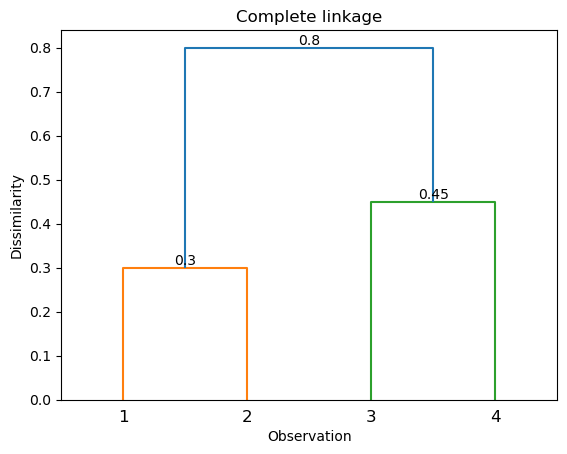

In [15]:
complete_linkage = linkage(squareform(dissim_matrix),method="complete")
plot_dendrogram(complete_linkage, "Complete linkage")

### (b)

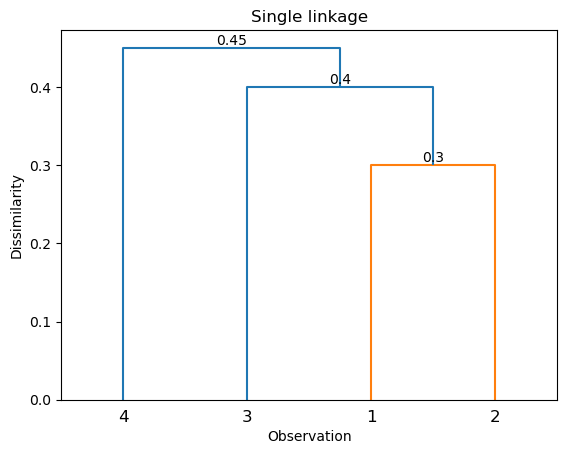

In [16]:
single_linkage = linkage(squareform(dissim_matrix),method="single")
plot_dendrogram(single_linkage, "Single linkage")

### (c)

**c answer**

{1, 2} and {3, 4}.

### (d)

**d answer**

{1, 2, 3} and {4}.

### (e)

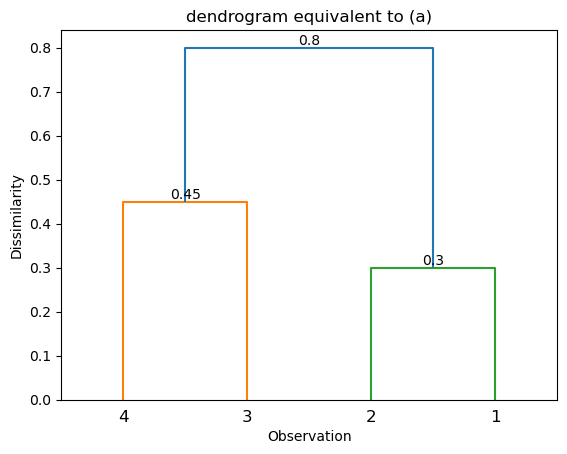

In [17]:
swapped = complete_linkage.copy()
swapped[:,[0, 1]] = swapped[:,[1, 0]]
plot_dendrogram(swapped,"dendrogram equivalent to (a)")